In [22]:
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
import random
from collections import Counter

In [3]:
data_path = Path("../data/raw/image")

In [4]:
for folder in data_path.iterdir():
    if folder.is_dir():
        images = list(folder.glob("*"))
        print(f"{folder.name}: {len(images)} images")

ASCUS: 782 images
HSIL: 1583 images
LSIL: 1339 images
NILM: 2101 images
SCC: 462 images


In [6]:
# Lets understand the class distribution.

class_counts = {
    "ASCUS": 782,
    "HSIL": 1583,
    "LSIL": 1339,
    "NILM": 2101,
    "SCC": 462
}

dist_df = pd.DataFrame(
    class_counts.items(),
    columns=['Class', 'Image_count']
)

dist_df

,Class,Image_count
0,ASCUS,782
1,HSIL,1583
2,LSIL,1339
3,NILM,2101
4,SCC,462


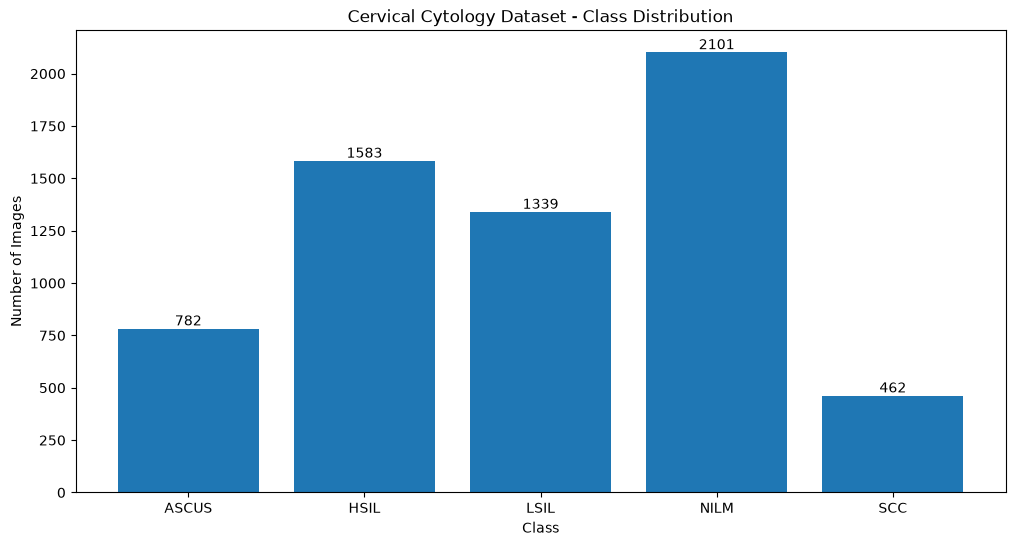

In [12]:
# Lets visualize it.

plt.figure(figsize=(12,6))

ax = plt.bar(dist_df['Class'], dist_df['Image_count'])

plt.bar_label(ax)

plt.title("Cervical Cytology Dataset - Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")

plt.show()

Our Dataset appears to be imbalanced. 

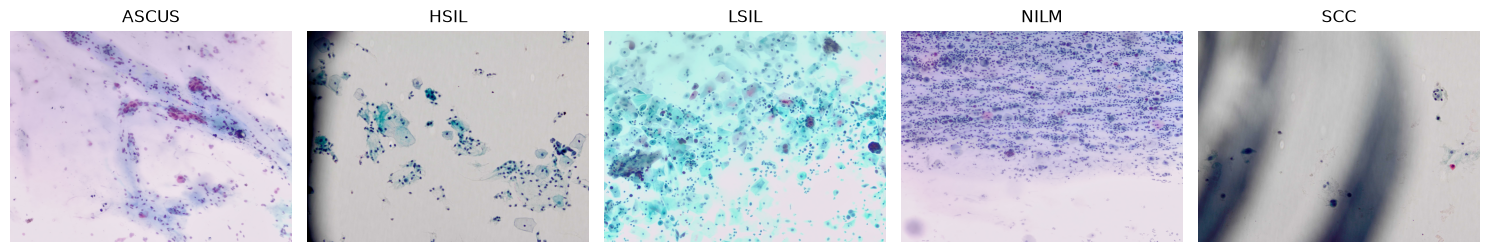

In [18]:
classes = ['ASCUS', 'HSIL', "LSIL", "NILM", "SCC"]

plt.figure(figsize=(15,8))

for i, class_name in enumerate(classes):

    folder = data_path / class_name

    image_files = list(folder.glob("*.jpg"))

    image_path = random.choice(image_files)

    img = Image.open(image_path)

    plt.subplot(1, 5, i+1)
    plt.imshow(img)

    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
image_sizes = []

for class_name in classes:

    folder = data_path/class_name

    for image_path in folder.glob("*.jpg"):
        with Image.open(image_path) as img:
            image_sizes.append(img.size)


size_counts = Counter(image_sizes)

print("Unique Image Dimensions: ", len(size_counts))

for size, count in size_counts.most_common(10):
    print(f"{size}: {count} Images")

Unique Image Dimensions:  4
(2592, 1944): 2692 Images
(2560, 1920): 1622 Images
(2048, 1536): 962 Images
(1654, 2338): 50 Images


In [26]:
# Lets check the formats of the images:

image_modes = Counter()

for class_name in classes:

    folder = data_path/class_name

    for image_path in folder.rglob("*.jpg"):
        with Image.open(image_path) as img:
            image_modes[img.mode] += 1


print(image_modes)

Counter({'RGB': 5326})


In [25]:
from collections import Counter

extensions = Counter()

for class_name in classes:
    folder = data_path / class_name

    for image_path in folder.rglob("*"):
        if image_path.is_file():
            extensions[image_path.suffix.lower()] += 1

print(extensions)

Counter({'.jpg': 5326, '.png': 941})


In [29]:
# There are two different Image formats here

image_sizes = Counter()
image_modes = Counter()

for class_name in classes:

    folder = data_path/class_name

    for image_path in folder.rglob("*"):

        if image_path.suffix.lower() in [".jpg", '.png', '.jpeg']:

            try: 
                with Image.open(image_path) as img:
                    image_sizes[img.size] += 1
                    image_modes[img.mode] += 1

            except Exception as e:
                print("Error: ", image_path, e)

print("Image Dimensions")
print(image_sizes)

print("\nImage Modes:")
print(image_modes)

Image Dimensions
Counter({(2592, 1944): 2692, (2560, 1920): 1622, (2048, 1536): 962, (1024, 1024): 941, (1654, 2338): 50})

Image Modes:
Counter({'RGB': 6267})


In [31]:
# Lets verify if all the images are valid and not corrupt

corrupted_images = []

for class_name in classes:

    folder = data_path/class_name

    for image_path in folder.glob("*"):

        if image_path.suffix.lower() in [".jpg", ".jpeg", "*png"]:

            try:
                with Image.open(image_path) as img:
                    img.verify()

            except:
                corrupted_images.append(image_path)

print("Total Corrupted Images: ", len(corrupted_images))
    

Total Corrupted Images:  0


Data Audit Is complete.